## Time response of linear systems

A linear time invariant system is represented by

$$G(s)=\frac{Y(s)}{U(s)}$$

Two signals reveal most dynamic properties:

- impulse input → impulse response
- step input → step response

The impulse response fully characterizes the system because any output can be written as

$$y(t)=\int_0^t h(\tau)u(t-\tau)d\tau$$

Signal energy is approximated numerically with

$$E=\int h(t)^2 dt$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import ipywidgets as widgets
from ipywidgets import interact

## First order system

$$G(s)=\frac{K}{\tau s+1}$$

- $K$ controls steady-state gain
- $\tau$ controls speed of response

Small $\tau$ → fast response. Large $\tau$ → slow response.

In [ ]:
def first_order(K=1.0, tau=1.0):
    num=[K]
    den=[tau,1]
    sys=signal.TransferFunction(num,den)

    t=np.linspace(0,10,600)
    t1,y1=signal.impulse(sys,T=t)
    t2,y2=signal.step(sys,T=t)

    energy=np.trapezoid(y1**2,t1)

    ymax=max(np.max(y1),np.max(y2))*1.2
    ymin=min(np.min(y1),np.min(y2))*1.2

    plt.figure()
    plt.plot(t1,y1,label='impulse response')
    plt.plot(t2,y2,label='step response')
    plt.grid(True)
    plt.xlim(0,10)
    plt.ylim(ymin,ymax)
    plt.xlabel('time')
    plt.ylabel('output')
    plt.title(f'First order system  |  energy={energy:.3f}')
    plt.legend()
    plt.show()

interact(first_order,
         K=widgets.FloatSlider(value=1,min=0.2,max=5,step=0.2),
         tau=widgets.FloatSlider(value=1,min=0.1,max=5,step=0.1));

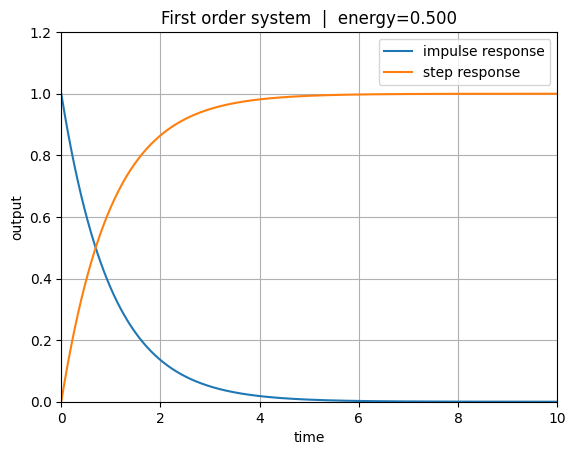

In [ ]:
# Hero figure — the one static image this notebook shows on GitHub.
first_order(K=(widgets.FloatSlider(value=1, min=0.2, max=5, step=0.2)).value, tau=(widgets.FloatSlider(value=1, min=0.1, max=5, step=0.1)).value)

## Second order system

$$G(s)=\frac{\omega_n^2}{s^2+2\zeta\omega_n s+\omega_n^2}$$

- $\omega_n$ controls oscillation speed
- $\zeta$ controls damping

Low damping produces oscillations. High damping removes oscillation.

In [ ]:
def second_order(wn=2.0,zeta=0.3):
    num=[wn**2]
    den=[1,2*zeta*wn,wn**2]
    sys=signal.TransferFunction(num,den)

    t=np.linspace(0,10,800)
    t_step,y_step=signal.step(sys,T=t)
    t_imp,y_imp=signal.impulse(sys,T=t)

    ymax=max(np.max(y_step),np.max(y_imp))*1.2
    ymin=min(np.min(y_step),np.min(y_imp))*1.2

    plt.figure()
    plt.plot(t_step,y_step,label='step response')
    plt.plot(t_imp,y_imp,label='impulse response')
    plt.grid(True)
    plt.xlim(0,10)
    plt.ylim(ymin,ymax)
    plt.xlabel('time')
    plt.ylabel('output')
    plt.title('Second order system')
    plt.legend()
    plt.show()

interact(second_order,
         wn=widgets.FloatSlider(value=2,min=0.5,max=10,step=0.5),
         zeta=widgets.FloatSlider(value=0.3,min=0,max=2,step=0.05));

## Pole movement in the complex plane

For the second order system the poles are

$$s=-\zeta\omega_n \pm j\omega_n\sqrt{1-\zeta^2}$$

The real part determines decay speed while the imaginary part determines oscillation frequency.

In [ ]:
def pole_plot(wn=2.0,zeta=0.3):
    real=-zeta*wn
    imag=wn*np.sqrt(max(0,1-zeta**2))

    poles=[complex(real,imag),complex(real,-imag)]

    limit=max(wn*1.5,2)

    plt.figure()
    plt.scatter([p.real for p in poles],[p.imag for p in poles])
    plt.axhline(0)
    plt.axvline(0)
    plt.grid(True)
    plt.xlim(-limit,limit)
    plt.ylim(-limit,limit)
    plt.xlabel('real')
    plt.ylabel('imag')
    plt.title('Pole location in complex plane')
    plt.show()

interact(pole_plot,
         wn=widgets.FloatSlider(value=2,min=0.5,max=10,step=0.5),
         zeta=widgets.FloatSlider(value=0,min=0,max=2,step=0.05));